## A1. Deskripsi Dataset
Dataset **`tips`** berasal dari library Seaborn. Dataset ini berisi catatan mengenai tip yang diberikan di sebuah restoran.
- **Jumlah Baris & Kolom:** 244 baris dan 7 kolom.
- **Fitur:** `total_bill` (total tagihan), `sex` (jenis kelamin pemberi tip), `smoker` (status perokok), `day` (hari), `time` (waktu makan), `size` (jumlah orang dalam rombongan).
- **Variabel Target:** `tip` (jumlah tip yang diberikan dalam bentuk numerik kontinu).

Statistik Deskriptif:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


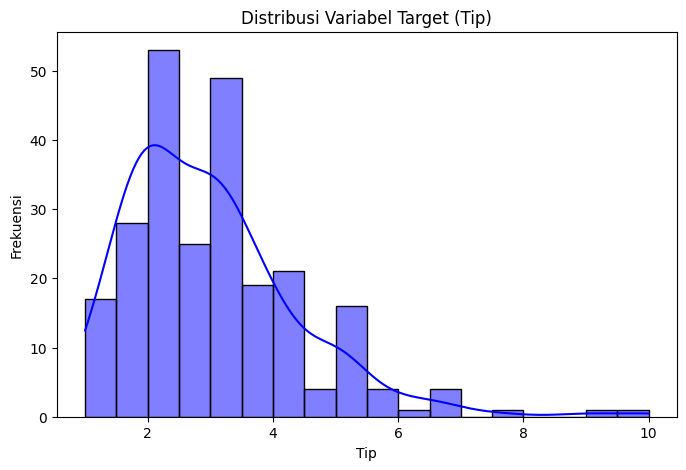

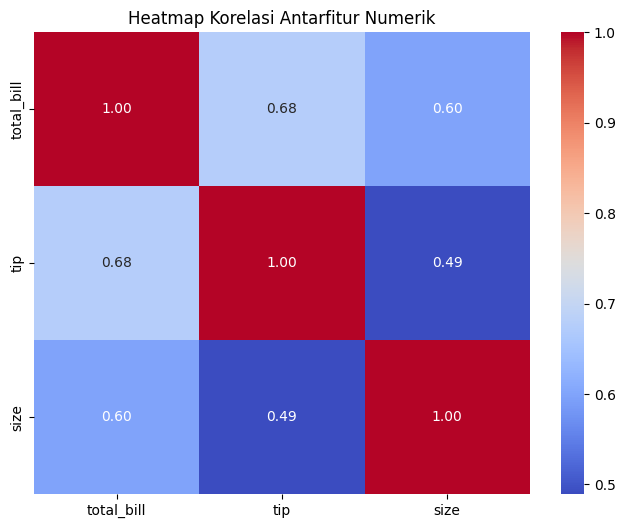

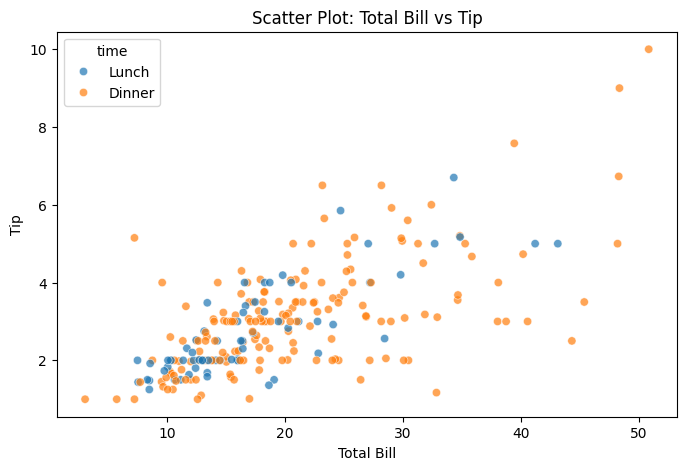

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Memuat dataset
df_tips = sns.load_dataset('tips')

# Statistik deskriptif
print("Statistik Deskriptif:")
display(df_tips.describe())

# Visualisasi 1: Histogram distribusi variabel target (tip)
plt.figure(figsize=(8, 5))
sns.histplot(df_tips['tip'], kde=True, color='blue')
plt.title('Distribusi Variabel Target (Tip)')
plt.xlabel('Tip')
plt.ylabel('Frekuensi')
plt.show()

# Visualisasi 2: Heatmap korelasi antarfitur numerik
plt.figure(figsize=(8, 6))
sns.heatmap(df_tips.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap Korelasi Antarfitur Numerik')
plt.show()

# Visualisasi 3: Scatter plot total_bill terhadap tip
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_tips, x='total_bill', y='tip', hue='time', alpha=0.7)
plt.title('Scatter Plot: Total Bill vs Tip')
plt.xlabel('Total Bill')
plt.ylabel('Tip')
plt.show()

## Temuan dari Visualisasi:
1. **Histogram Target (`tip`):** Distribusi target sedikit miring ke kanan (*right-skewed*), di mana sebagian besar tip berkisar antara $2 hingga $4.
2. **Heatmap Korelasi:** Fitur `total_bill` dan `size` memiliki korelasi positif yang kuat terhadap variabel target `tip`.
3. **Scatter Plot:** Menunjukkan tren linier yang jelas; semakin besar total tagihan (`total_bill`), cenderung semakin besar pula jumlah `tip` yang diberikan.


In [ ]:
from sklearn.model_selection import train_test_split

# Cek missing values & duplikat
print("Missing values:\n", df_tips.isnull().sum())
print("Jumlah duplikat:", df_tips.duplicated().sum())

# A4. Pemilihan Fitur & X, y splitting
# Menggunakan fitur numerik dan kategorikal yang relevan
X = df_tips[['total_bill', 'size', 'sex', 'smoker', 'day', 'time']]
y = df_tips['tip']

# A5. Pembagian Data (80:20) dengan random_state
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Ukuran Data Latih:", X_train.shape)
print("Ukuran Data Uji:", X_test.shape)


Missing values:
 total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64
Jumlah duplikat: 1
Ukuran Data Latih: (195, 6)
Ukuran Data Uji: (49, 6)


--- Evaluasi Data Latih ---
MAE: 0.7599651398627899
RMSE: 1.0491326804711238
R2 Score: 0.45824907818983895

--- Evaluasi Data Uji ---
MAE: 0.667133148026489
RMSE: 0.8386635807900624
R2 Score: 0.4373018194348257


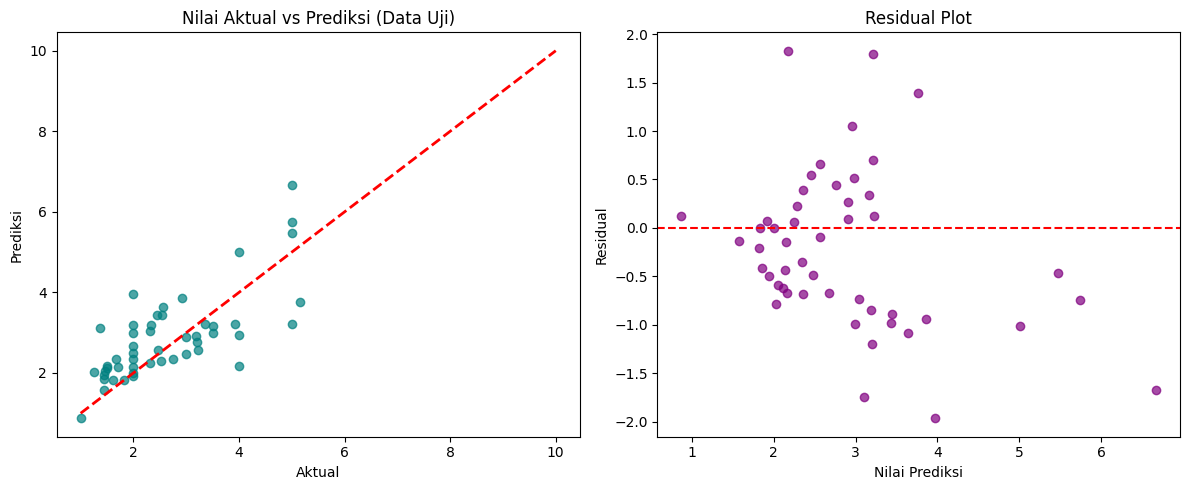

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Menangani fitur kategorikal dengan OneHotEncoder dalam Pipeline
categorical_features = ['sex', 'smoker', 'day', 'time']
preprocessor = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(drop='first'), categorical_features)],
    remainder='passthrough'
)

model_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# A6. Pelatihan Model
model_lr.fit(X_train, y_train)

# Prediksi
y_pred_train = model_lr.predict(X_train)
y_pred_test = model_lr.predict(X_test)

# A7. Evaluasi Metrik
print("--- Evaluasi Data Latih ---")
print("MAE:", mean_absolute_error(y_train, y_pred_train))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_pred_train)))
print("R2 Score:", r2_score(y_train, y_pred_train))

print("\n--- Evaluasi Data Uji ---")
print("MAE:", mean_absolute_error(y_test, y_pred_test))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_test)))
print("R2 Score:", r2_score(y_test, y_pred_test))

# Visualisasi Aktual vs Prediksi & Residual Plot
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_test, alpha=0.7, color='teal')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.xlabel('Aktual')
plt.ylabel('Prediksi')
plt.title('Nilai Aktual vs Prediksi (Data Uji)')

plt.subplot(1, 2, 2)
residuals = y_test - y_pred_test
plt.scatter(y_pred_test, residuals, alpha=0.7, color='purple')
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Nilai Prediksi')
plt.ylabel('Residual')
plt.title('Residual Plot')
plt.tight_layout()
plt.show()
